# Домашнее задание по теме «Ансамбли»

В этом задании ты потренируешься реализовывать пайплайн обучения ML-моделей и проверишь, помогут ли в реальной задаче ансамбли деревьев. В задании приветствуются твои размышления и предположения.

> ### Правила домашнего задания
>1. Нельзя удалять существующие ячейки кода.
>
>2. Можно добавлять и дописывать свои ячейки.
>
>3. Место, куда тебе нужно написать код, помечается комментарием.
>
> 4. Ответ без кода, который подтвердит твоё решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется и нужно сделать вывод из известных данных.
>
> 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.
>
> 6. Визуализации обязательны.
>
> 7. Все графики подписывай так, чтобы можно было легко понять их суть. Избегай слишком мелкого или крупного текста, подписывай оси на одном языке.
>
> 8. Оформляй все выводы (портрет банка, портрет клиента, бизнес-решение) в markdown-тексте.
>
> 9. Фиксируй `random_state` для воспроизводимости результатов.


## Легенда


Ты претендуешь на позицию главного аналитика небольшого банка.

Предыдущего аналитика уличили в мошеннической схеме и выгнали с позором. Его работа привела банк к финансовым проблемам, поэтому тебе доверили заняться оптимизацией выдачи кредитов — ещё не успели посвятить в тонкости, но работы уже подкинули.

Твоя задача — быстро разобраться в данных, найти закономерности и предложить несколько ML-моделей, которые могут ускорить принятие решений. От того, как хорошо ты справишься, зависит твоё будущее и будущее банка. О подробностях задания — читай ниже. Удачи!



## О датасете

Банк предоставил историю заявок на кредит. Каждую заявку проверял кредитный комитет: сотрудники вручную смотрели документы и решали, одобрить кредит или нет. Проверка идёт долго, поэтому банк хочет, чтобы модель заранее отбирала заявки, которые комитет одобрил бы.

Целевая переменная: `Loan_Status` — решение кредитного комитета по заявке.
* `Y` — заявку одобрили. Таких клиентов дальше будем называть «хорошими».
* `N` — в кредите отказали. Это «плохие» клиенты.

* `Loan_ID` — идентификатор заявки.
* `Gender` — пол заявителя (`Male` — мужчина, `Female` — женщина).
* `Married` — семейное положение (`Yes` — состоит в браке, `No` — не состоит).
* `Dependents` — количество иждивенцев у заявителя (`0`, `1`, `2`, `3+` — три и более).
* `Education` — уровень образования (`Graduate` — есть высшее образование, `Not Graduate` — нет).
* `Self_Employed` — занятость (`Yes` — самозанятый/предприниматель, `No` — работает по найму).
* `ApplicantIncome` — ежемесячный доход основного заявителя.
* `CoapplicantIncome` — ежемесячный доход созаёмщика (если созаёмщика нет, стоит `0`).
* `LoanAmount` — сумма кредита, которую запрашивает клиент, в тысячах (валюту банк не сообщил).
* `Loan_Amount_Term` — срок кредита в месяцах.
* `Credit_History` — соответствует ли кредитная история требованиям банка (`1` — соответствует, `0` — нет).
* `Property_Area` — где находится недвижимость заявителя (`Urban` — город, `Semiurban` — пригород, `Rural` — сельская местность).

## Задание 1 [4 балла]

Проведи EDA. Эта часть домашнего задания проверит твои аналитические навыки.

1) Найди зависимости между признаками **[1 балл].**
2) Найди корреляции или зависимости с целевой переменной **[1 балл].**
3) Подготовь данные к четвёртому пункту задания — обработай пропуски и предобработай категориальные признаки **[1 балл].**
4) На основе датасета опиши самые значимые и характерные признаки, приведи ключевые статистики и составь портреты: сделай выводы о природе поведения **[1 балл]:**
    - банка,
    - типичного «хорошего» клиента — того, кому выдавали кредит,
    - типичного «плохого» клиента — того, кому не выдавали кредит.

К каждому пункту задания добавь:

- не менее одной иллюстрации или одного графика;
- не менее одного вывода. В выводах должен быть развёрнутый ответ с твоими мыслями, а не сухие факты.

В задании приветствуется творческий подход — запись промежуточных выводов:
- по графикам;
- посчитанным значениям;
- стратегии заполнения пропусков и так далее.

In [1]:
!gdown 1hEQp8v8xUSTnNyZjiY7pGZvmzfczib19

Using cookies from /home/igor/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1hEQp8v8xUSTnNyZjiY7pGZvmzfczib19
To: /home/igor/dev/competitive-py/ai/dataset.csv
100%|█████████████████████████████████████| 38.0k/38.0k [00:00<00:00, 73.2kB/s]


In [2]:
# Напиши код здесь
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("dataset.csv")
print(df.shape)
df.head()

(614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


### 1.1. Пропуски, баланс классов и распределения признаков

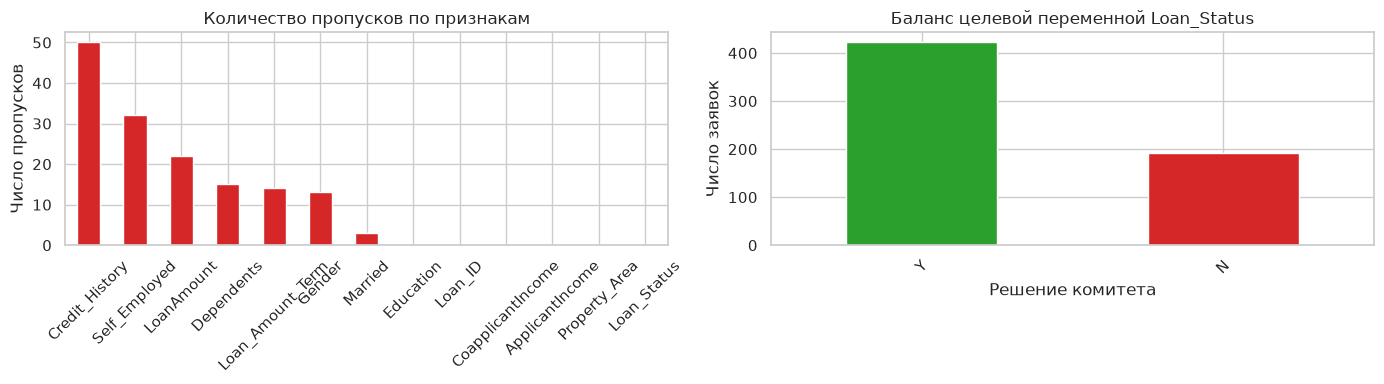

Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.isna().sum().sort_values(ascending=False).plot.bar(ax=axes[0], color="tab:red")
axes[0].set_title("Количество пропусков по признакам")
axes[0].set_ylabel("Число пропусков")
df["Loan_Status"].value_counts().plot.bar(ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set_title("Баланс целевой переменной Loan_Status")
axes[1].set_xlabel("Решение комитета")
axes[1].set_ylabel("Число заявок")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(df["Loan_Status"].value_counts(normalize=True).round(3))

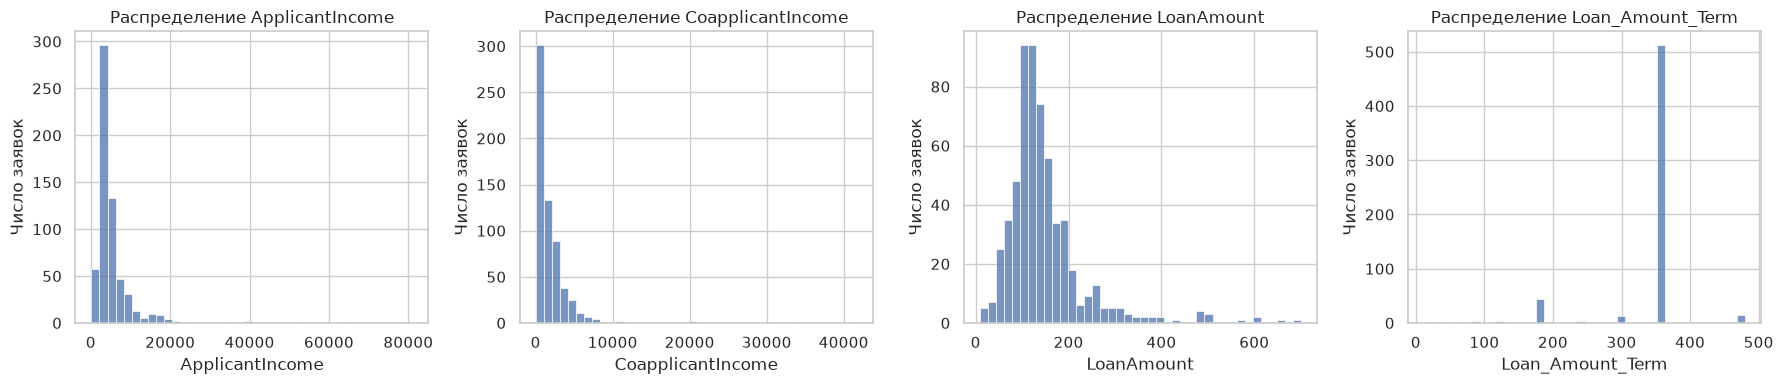

ApplicantIncome      6.54
CoapplicantIncome    7.49
LoanAmount           2.68
Loan_Amount_Term    -2.36
dtype: float64

In [5]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set_title(f"Распределение {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Число заявок")
plt.tight_layout()
plt.show()
df[num_cols].skew().round(2)

Распределения доходов и суммы кредита сильно скошены вправо (длинный хвост богатых заявителей), а `Loan_Amount_Term` почти константа: подавляющее большинство кредитов берут на 360 месяцев (30 лет). Для анализа зависимостей будем использовать логарифмы доходов/суммы и ранговые корреляции.

### 1.2. Зависимости между признаками

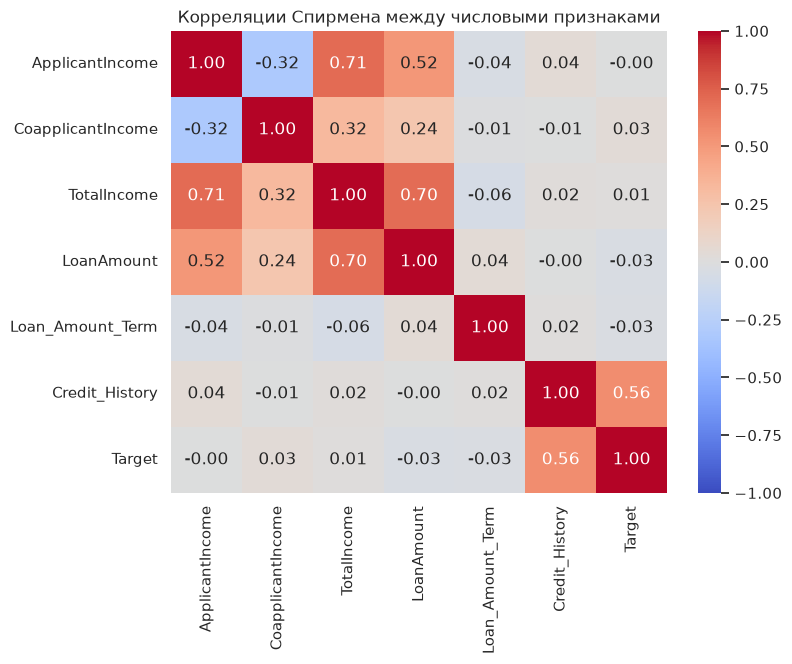

In [6]:
eda = df.copy()
eda["TotalIncome"] = eda["ApplicantIncome"] + eda["CoapplicantIncome"]
eda["LogTotalIncome"] = np.log1p(eda["TotalIncome"])
eda["LogLoanAmount"] = np.log1p(eda["LoanAmount"])
eda["Target"] = (eda["Loan_Status"] == "Y").astype(int)

corr_cols = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "TotalIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Target",
]
plt.figure(figsize=(8, 6))
sns.heatmap(
    eda[corr_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Корреляции Спирмена между числовыми признаками")
plt.show()

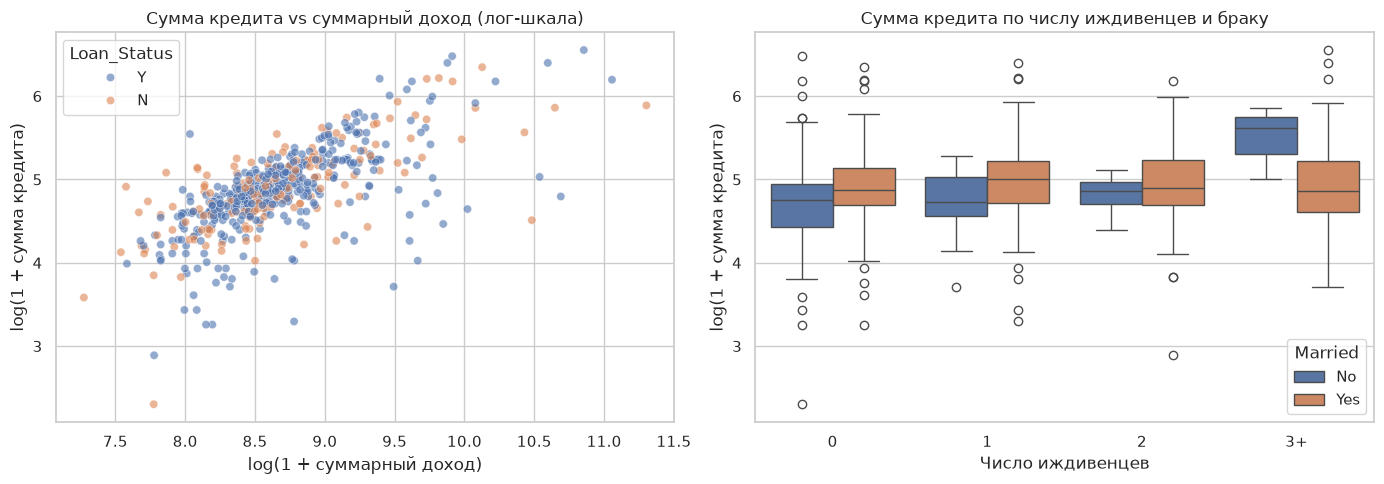

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=eda,
    x="LogTotalIncome",
    y="LogLoanAmount",
    hue="Loan_Status",
    alpha=0.6,
    ax=axes[0],
)
axes[0].set_title("Сумма кредита vs суммарный доход (лог-шкала)")
axes[0].set_xlabel("log(1 + суммарный доход)")
axes[0].set_ylabel("log(1 + сумма кредита)")

sns.boxplot(data=eda, x="Dependents", y="LogLoanAmount", hue="Married", ax=axes[1])
axes[1].set_title("Сумма кредита по числу иждивенцев и браку")
axes[1].set_xlabel("Число иждивенцев")
axes[1].set_ylabel("log(1 + сумма кредита)")
plt.tight_layout()
plt.show()

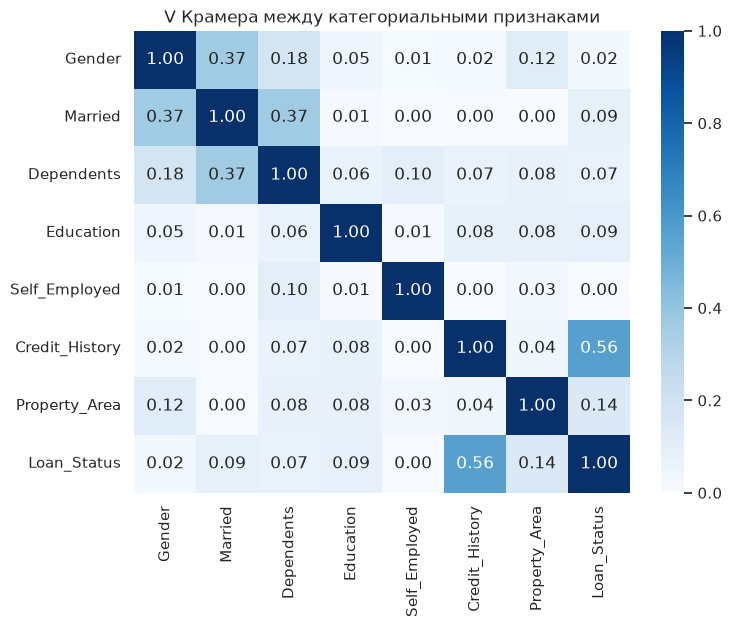

In [8]:
# Зависимости между категориальными признаками: V Крамера
from scipy.stats import chi2_contingency

cat_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area",
    "Loan_Status",
]


def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))


cv = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for a in cat_cols:
    for b in cat_cols:
        cv.loc[a, b] = cramers_v(eda[a], eda[b])

plt.figure(figsize=(8, 6))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("V Крамера между категориальными признаками")
plt.show()

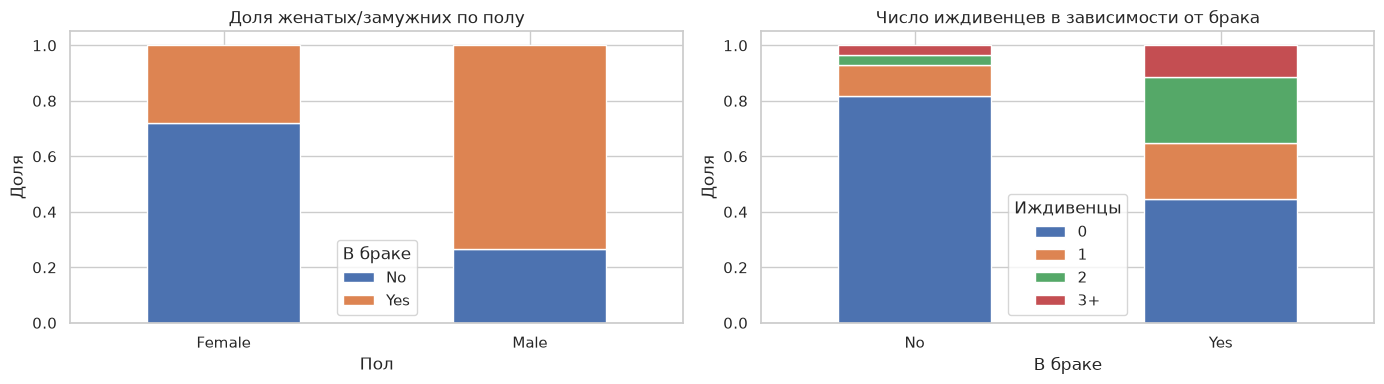

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(eda["Gender"], eda["Married"], normalize="index").plot.bar(
    stacked=True, ax=axes[0]
)
axes[0].set_title("Доля женатых/замужних по полу")
axes[0].set_xlabel("Пол")
axes[0].set_ylabel("Доля")
axes[0].legend(title="В браке")
pd.crosstab(eda["Married"], eda["Dependents"], normalize="index").plot.bar(
    stacked=True, ax=axes[1]
)
axes[1].set_title("Число иждивенцев в зависимости от брака")
axes[1].set_xlabel("В браке")
axes[1].set_ylabel("Доля")
axes[1].legend(title="Иждивенцы")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 1.3. Зависимости с целевой переменной

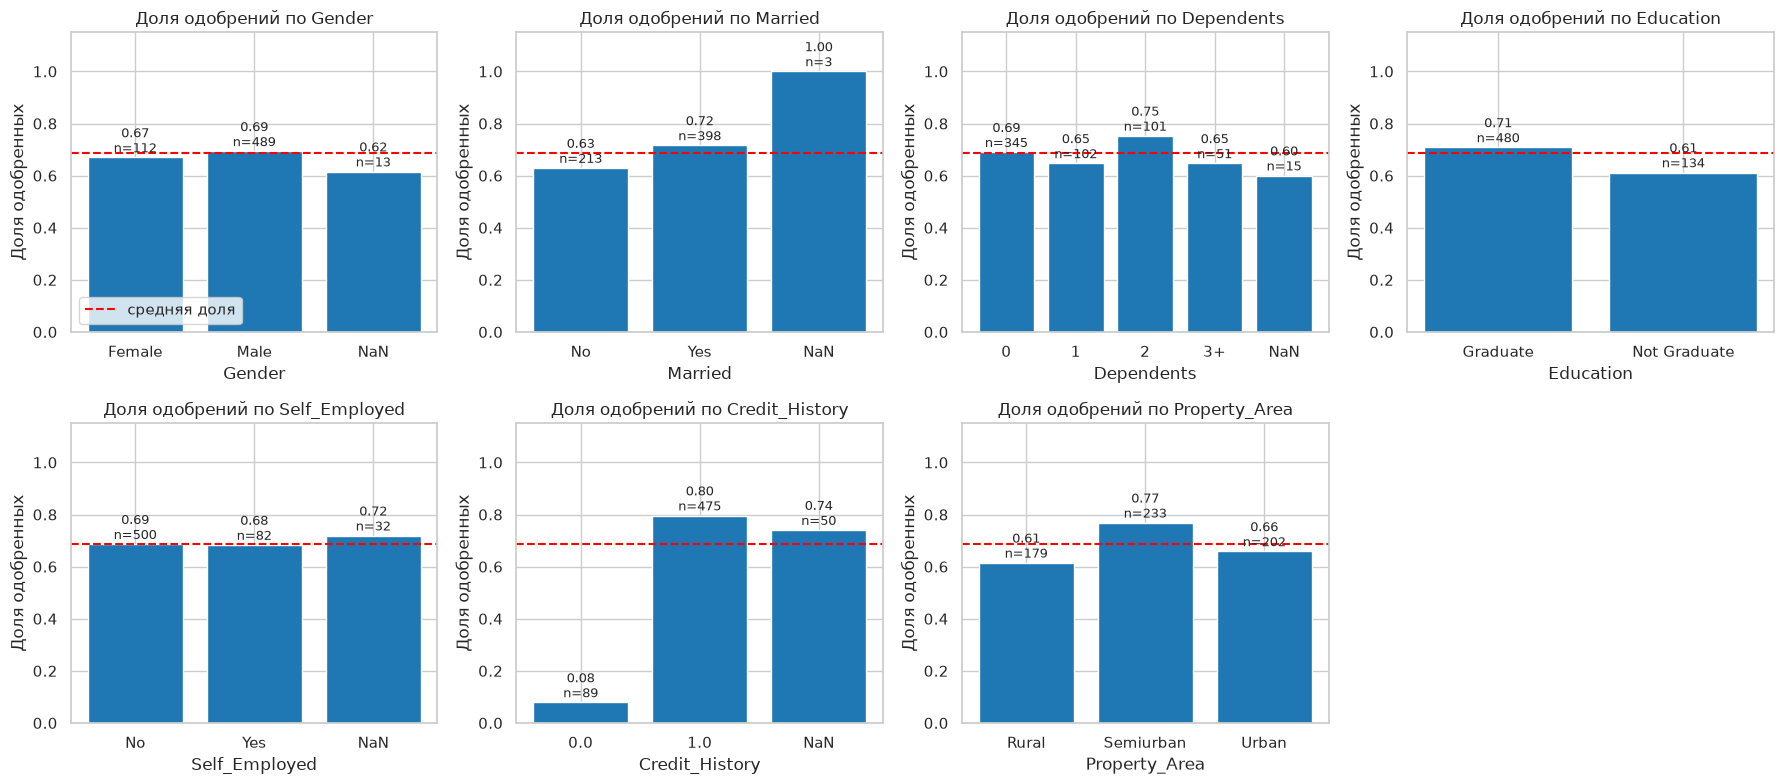

In [10]:
cat_feats = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area",
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_feats):
    rate = eda.groupby(col, dropna=False)["Target"].agg(["mean", "size"])
    rate.index = ["NaN" if pd.isna(v) else str(v) for v in rate.index]
    ax.bar(rate.index, rate["mean"], color="tab:blue")
    ax.axhline(eda["Target"].mean(), color="red", ls="--", label="средняя доля")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, m + 0.02, f"{m:.2f}\nn={n}", ha="center", fontsize=9)
    ax.set_ylim(0, 1.15)
    ax.set_title(f"Доля одобрений по {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Доля одобренных")
axes[0, 0].legend(loc="lower left")
axes[1, 3].axis("off")
plt.tight_layout()
plt.show()

In [11]:
# Статистическая значимость связи категориальных признаков с таргетом
rows = []
for col in cat_feats:
    tab = pd.crosstab(eda[col], eda["Loan_Status"])
    chi2, p, *_ = chi2_contingency(tab)
    rows.append(
        {
            "feature": col,
            "cramers_v": cramers_v(eda[col], eda["Loan_Status"]),
            "p_value": p,
        }
    )
pd.DataFrame(rows).sort_values("cramers_v", ascending=False).round(4)

,feature,cramers_v,p_value
5,Credit_History,0.5617,0.0000
6,Property_Area,0.1415,0.0021
1,Married,0.0893,0.0344
3,Education,0.0859,0.0431
2,Dependents,0.0726,0.3679
0,Gender,0.0199,0.7087
4,Self_Employed,0.0023,1.0000


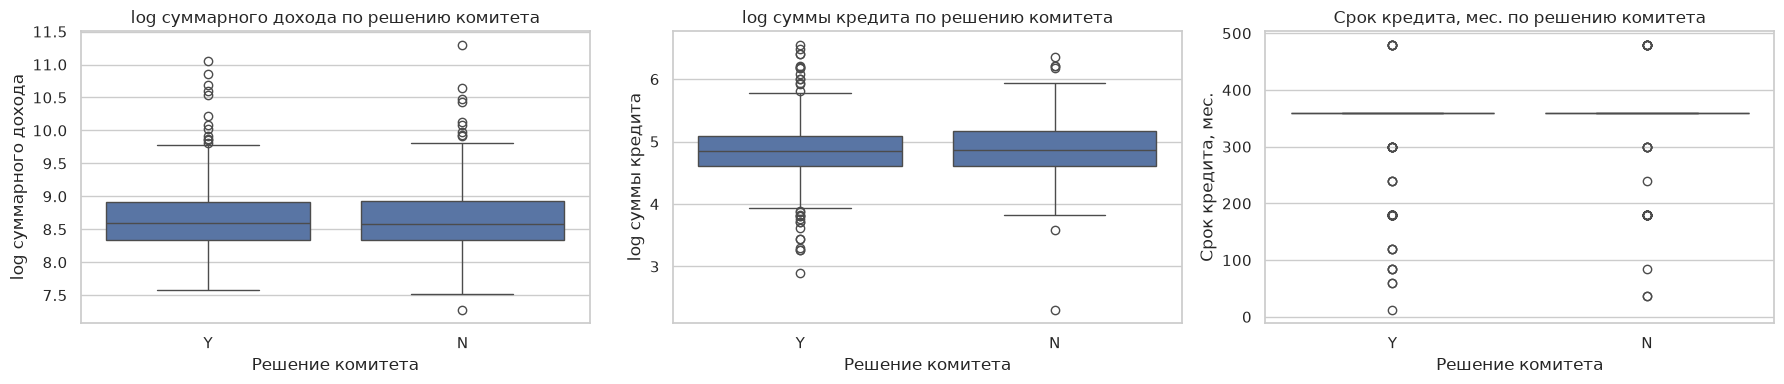

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,LoanToIncome
Loan_Status,,,,,
N,3833.5,268.0,5289.5,129.0,23.8
Y,3812.5,1239.5,5439.0,126.0,24.3


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, title in zip(
    axes,
    ["LogTotalIncome", "LogLoanAmount", "Loan_Amount_Term"],
    ["log суммарного дохода", "log суммы кредита", "Срок кредита, мес."],
):
    sns.boxplot(data=eda, x="Loan_Status", y=col, ax=ax)
    ax.set_title(f"{title} по решению комитета")
    ax.set_xlabel("Решение комитета")
    ax.set_ylabel(title)
plt.tight_layout()
plt.show()

eda["LoanToIncome"] = eda["LoanAmount"] * 1000 / eda["TotalIncome"]
eda.groupby("Loan_Status")[
    [
        "ApplicantIncome",
        "CoapplicantIncome",
        "TotalIncome",
        "LoanAmount",
        "LoanToIncome",
    ]
].median().round(1)

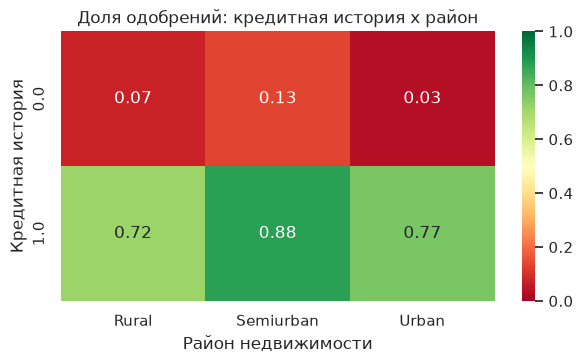

In [13]:
# Кредитная история x район: самая сильная пара факторов
pivot = eda.pivot_table(
    index="Credit_History", columns="Property_Area", values="Target", aggfunc="mean"
)
plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Доля одобрений: кредитная история x район")
plt.xlabel("Район недвижимости")
plt.ylabel("Кредитная история")
plt.show()

### 1.4. Обработка пропусков и категориальных признаков

In [14]:
print(df.isna().sum()[df.isna().sum() > 0])
# Одобрение у заявок с пропущенной кредитной историей
print(
    "\nДоля одобрений при пропуске Credit_History:",
    round(eda.loc[eda["Credit_History"].isna(), "Target"].mean(), 3),
)

Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

Доля одобрений при пропуске Credit_History: 0.74


**Стратегия заполнения пропусков:**
* `Credit_History` (50 пропусков) - самый важный признак, поэтому не заполняем его модой вслепую: доля одобрений у пропусков близка к средней (между 0 и 1), то есть это отдельная группа. Добавляем флаг `Credit_History_missing` и заполняем пропуск модой (1).
* `Gender`, `Married`, `Dependents`, `Self_Employed` - немного пропусков, заполняем модой.
* `LoanAmount` - медианой (распределение скошено, медиана устойчивее среднего).
* `Loan_Amount_Term` - модой (360).
* Новые признаки: суммарный доход, логарифмы, отношение суммы кредита к доходу и примерный ежемесячный платёж к доходу.
* Категориальные признаки: бинарные - в 0/1, `Dependents` - в число (`3+` -> 3), `Property_Area` - one-hot.

Чтобы не было утечки, медианы/моды считаются на обучающей выборке внутри пайплайна (`SimpleImputer`), а здесь готовим "сырую" таблицу признаков.

In [15]:
def prepare_features(data: pd.DataFrame) -> pd.DataFrame:
    """Переводит заявки в числовые признаки (пропуски остаются NaN - их заполняет пайплайн)"""
    X = pd.DataFrame(index=data.index)
    X["Gender"] = data["Gender"].map({"Male": 1, "Female": 0})
    X["Married"] = data["Married"].map({"Yes": 1, "No": 0})
    X["Dependents"] = data["Dependents"].replace("3+", "3").astype(float)
    X["Education"] = data["Education"].map({"Graduate": 1, "Not Graduate": 0})
    X["Self_Employed"] = data["Self_Employed"].map({"Yes": 1, "No": 0})
    X["Credit_History"] = data["Credit_History"].astype(float)
    X["Credit_History_missing"] = data["Credit_History"].isna().astype(int)
    for area in ["Rural", "Semiurban", "Urban"]:
        X[f"Area_{area}"] = (data["Property_Area"] == area).astype(int)
    total = data["ApplicantIncome"] + data["CoapplicantIncome"]
    X["LogApplicantIncome"] = np.log1p(data["ApplicantIncome"])
    X["LogCoapplicantIncome"] = np.log1p(data["CoapplicantIncome"])
    X["LogTotalIncome"] = np.log1p(total)
    X["LogLoanAmount"] = np.log1p(data["LoanAmount"])
    X["Loan_Amount_Term"] = data["Loan_Amount_Term"].astype(float)
    X["LoanToIncome"] = data["LoanAmount"] * 1000 / total.replace(0, np.nan)
    X["EMIToIncome"] = (
        data["LoanAmount"] * 1000 / data["Loan_Amount_Term"] / total.replace(0, np.nan)
    )
    return X


X = prepare_features(df)
y = (df["Loan_Status"] == "Y").astype(int)
print(X.shape)
X.head()

(614, 17)


,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Credit_History_missing,Area_Rural,Area_Semiurban,Area_Urban,LogApplicantIncome,LogCoapplicantIncome,LogTotalIncome,LogLoanAmount,Loan_Amount_Term,LoanToIncome,EMIToIncome
0,1.0,0.0,0.0,1,0.0,1.0,0,0,0,1,8.674197,0.000000,8.674197,NaN,360.0,NaN,NaN
1,1.0,1.0,1.0,1,0.0,1.0,0,1,0,0,8.430327,7.319202,8.714732,4.859812,360.0,21.014612,0.058374
2,1.0,1.0,0.0,1,1.0,1.0,0,0,0,1,8.006701,0.000000,8.006701,4.204693,360.0,22.000000,0.061111
3,1.0,1.0,0.0,0,0.0,1.0,0,0,0,1,7.857094,7.765993,8.505525,4.795791,360.0,24.286582,0.067463
4,1.0,0.0,0.0,1,0.0,1.0,0,0,0,1,8.699681,0.000000,8.699681,4.955827,360.0,23.500000,0.065278


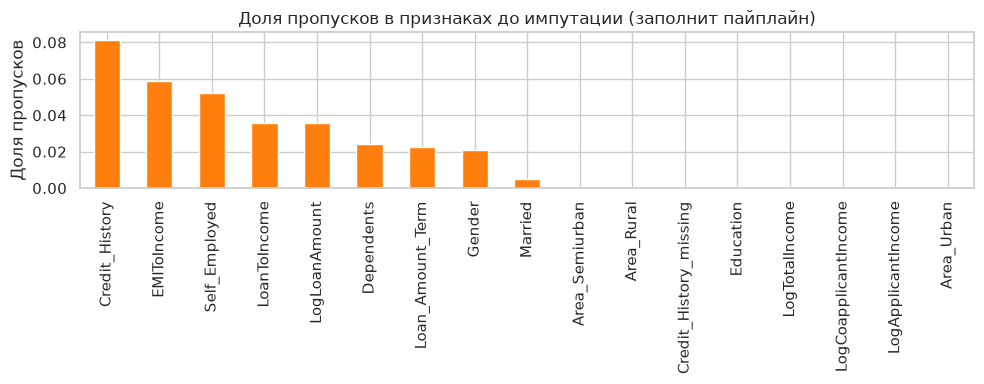

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
X.isna().mean().sort_values(ascending=False).plot.bar(ax=ax, color="tab:orange")
ax.set_title("Доля пропусков в признаках до импутации (заполнит пайплайн)")
ax.set_ylabel("Доля пропусков")
plt.tight_layout()
plt.show()

### 1.5. Портреты банка, "хорошего" и "плохого" клиента

In [17]:
portrait = eda.copy()
portrait["Credit_History"] = (
    portrait["Credit_History"].map({1.0: "1", 0.0: "0"}).fillna("нет данных")
)
summary = (
    pd.concat(
        {
            "Хорошие (Y)": portrait[portrait.Loan_Status == "Y"],
            "Плохие (N)": portrait[portrait.Loan_Status == "N"],
        },
        names=["group"],
    )
    .groupby(level="group")
    .agg(
        n=("Target", "size"),
        credit_history_ok=("Credit_History", lambda s: (s == "1").mean()),
        credit_history_bad=("Credit_History", lambda s: (s == "0").mean()),
        married=("Married", lambda s: (s == "Yes").mean()),
        graduate=("Education", lambda s: (s == "Graduate").mean()),
        self_employed=("Self_Employed", lambda s: (s == "Yes").mean()),
        semiurban=("Property_Area", lambda s: (s == "Semiurban").mean()),
        rural=("Property_Area", lambda s: (s == "Rural").mean()),
        has_coapplicant=("CoapplicantIncome", lambda s: (s > 0).mean()),
        median_total_income=("TotalIncome", "median"),
        median_loan=("LoanAmount", "median"),
        median_loan_to_income=("LoanToIncome", "median"),
    )
)
summary.T.round(3)

group,Плохие (N),Хорошие (Y)
n,192.000,422.000
credit_history_ok,0.505,0.896
credit_history_bad,0.427,0.017
married,0.589,0.675
graduate,0.729,0.806
self_employed,0.135,0.133
semiurban,0.281,0.424
rural,0.359,0.261
has_coapplicant,0.500,0.581
median_total_income,5289.500,5439.000


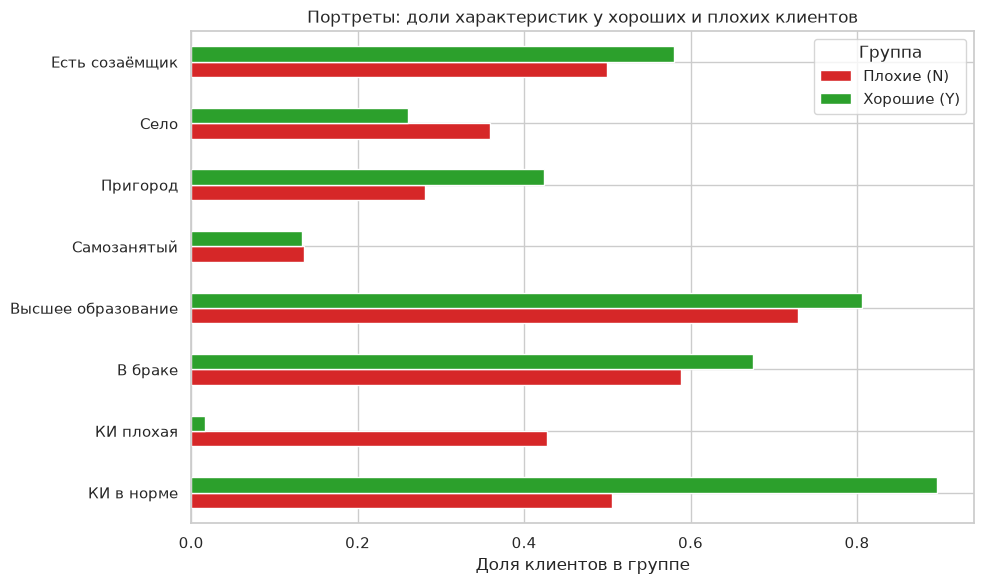

In [18]:
share_cols = [
    "credit_history_ok",
    "credit_history_bad",
    "married",
    "graduate",
    "self_employed",
    "semiurban",
    "rural",
    "has_coapplicant",
]
labels = [
    "КИ в норме",
    "КИ плохая",
    "В браке",
    "Высшее образование",
    "Самозанятый",
    "Пригород",
    "Село",
    "Есть созаёмщик",
]
ax = (
    summary[share_cols]
    .T.set_axis(labels)
    .plot.barh(figsize=(10, 6), color=["tab:red", "tab:green"])
)
ax.set_title("Портреты: доли характеристик у хороших и плохих клиентов")
ax.set_xlabel("Доля клиентов в группе")
ax.legend(title="Группа")
plt.tight_layout()
plt.show()

## Выводы по заданию 1

Между признаками самая заметная связь у дохода заявителя и суммы кредита (Спирмен около 0.52): чем богаче клиент, тем больше он просит, и медианный кредит у всех примерно равен 24 месячным доходам семьи. Доход созаёмщика связан с доходом заявителя отрицательно (около -0.32), то есть созаёмщика привлекают те, кому своего дохода не хватает, поэтому разумнее смотреть на суммарный доход. Пол, брак и иждивенцы образуют единый "семейный профиль": 73% мужчин в браке против 28% женщин, а у семейных иждивенцы есть в 55% случаев против 18% у несемейных. Срок кредита почти всегда 360 месяцев и почти ничего не добавляет.

С целевой переменной сильнее всего связана кредитная история (V Крамера 0.56): при хорошей истории одобряют 80% заявок, при плохой всего 8%. Дальше с большим отрывом идёт район (пригород 77%, город 66%, село 61%), а брак и высшее образование дают слабый, но значимый плюс. Пол, самозанятость и число иждивенцев незначимы. Самое неожиданное, что доход и сумма кредита на решение почти не влияют: медианы у одобренных и отказников практически совпадают, лишь у хороших клиентов чаще есть созаёмщик.

Пропуски есть в семи признаках, больше всего в кредитной истории (50). Эти пропуски не случайны: одобряют там 74%, то есть "нет данных" ближе к хорошей истории, но не равно ей, поэтому я добавил флаг пропуска, а сам признак заполняю модой. Остальное заполняется медианой внутри пайплайна по обучающей выборке, чтобы не было утечки. Бинарные признаки переведены в 0/1, иждивенцы в число, район в one-hot, а доходы и сумма логарифмированы из-за сильной скошенности; ещё добавлены отношения кредита и платежа к доходу.

Банк выглядит консервативным и ориентированным прежде всего на кредитную историю: одобряет 69% заявок, но почти всегда отказывает при плохой истории, а платёжеспособность фактически не оценивает, что вполне могло привести к финансовым проблемам. Типичный хороший клиент - мужчина в браке с высшим образованием, работающий по найму, с хорошей кредитной историей (90%), из пригорода или города, часто с созаёмщиком, с доходом семьи около 5.4 тыс. и кредитом около 126 тыс. на 30 лет. Типичный плохой клиент по деньгам от него не отличается, но у 43% из них плохая кредитная история (у хороших 1.7%), он чаще живёт в селе и реже состоит в браке, имеет высшее образование или созаёмщика.


## Задание 2 [5 баллов]

### Описание

У банка финансовые трудности, поэтому руководство думает над двумя стратегиями выхода из кризиса. В обеих модель сама одобряет часть заявок. Остальные заявки, как и раньше, уходят в кредитный комитет.

| Стратегия  | Описание | Цель | Ограничение |
|----------------|----------------------------|---------------------------------|-------------------------------|
| «Новые горизонты» | Рискнуть и одобрять заявки активно, <br>чтобы быстро набрать клиентов | Одобрить как можно больше <br>хороших клиентов | Не менее 75% одобренных моделью заявок <br>должны быть хорошими. Финансисты рассчитали, <br>что это точка безубыточности |
| «Жёсткая экономия» | Свернуть активное кредитование <br>и без комитета одобрять только надёжных | Среди надёжных заявок одобрить <br>как можно больше хороших | Не менее 90% одобренных моделью заявок <br>должны быть хорошими |

Доля хороших среди одобренных моделью заявок — это `Precision`, а доля найденных хороших среди всех хороших — `Recall`. Значит, в каждой стратегии нужно подобрать порог классификации так, чтобы `Precision` был не ниже заданного, а `Recall` при этом был как можно больше.

> Порог мы подбираем прямо на тестовой выборке. В реальной работе так не делают: порог выбирают на отдельной выборке, а тестовую оставляют для финальной проверки. Подробнее об этом расскажут в курсе машинного обучения.

### Что нужно сделать

1) Построй не менее двух моделей из тех, что мы проходили раньше: логистическую регрессию, KNN или одиночное решающее дерево. Для каждой модели подбери пороги под обе стратегии и посчитай на тестовой выборке `Precision`, `Recall` и долю одобренных заявок **[1 балл]**.

2) Проверь, помогут ли ансамбли **[2 балла]**:
    - обучи случайный лес и градиентный бустинг и посчитай для них то же, что в пункте 1;
    - тестовая выборка небольшая, поэтому результат одного разбиения сильно зависит от того, какие заявки в неё попали. Сравни все модели ещё раз на 20 разных разбиениях с помощью готовой функции `evaluate_on_splits` и посмотри на средний `Recall` в каждой стратегии;
    - для случайного леса проверь, как меняется средний `Recall` в «Жёсткой экономии», если деревьев 1, 5, 20, 100 и 300. Построй график;
    - сделай вывод: помогли ли ансамбли и почему лес из многих деревьев работает иначе, чем одно дерево.

3) Сравни построенные модели между собой. Выбери лучшую модель для каждой стратегии и поясни своё решение с опорой на показатели: `Precision`, `Recall`, долю одобренных заявок, интерпретируемость. Обязательно фиксируй свои мысли и развёрнутые выводы **[1 балл]**.

4) Оформи блок кода, позволяющий ввести данные заявителя вручную и получить ответ: одобрила бы модель кредит или нет (руководство хочет оценить модели лично) **[1 балл]**.

In [19]:
# Готовые функции, они пригодятся в пунктах 1 и 2

from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import train_test_split


def find_threshold(y_true, proba, min_precision):
    """Порог, при котором Precision не ниже min_precision, а Recall максимальный.
    Если такого порога нет, возвращает None"""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    # precision и recall на один элемент длиннее, чем пороги:
    # последняя пара (precision = 1, recall = 0) ни одному порогу не соответствует
    prec, rec = prec[:-1], rec[:-1]

    feasible = prec >= min_precision
    if not np.any(feasible):
        return None

    best_idx = np.argmax(rec[feasible])
    return float(thr[feasible][best_idx])


def metrics_at_threshold(y_true, proba, thr):
    """Precision, Recall и доля одобренных заявок при заданном пороге.
    Если порога нет (thr=None), модель никому не одобряет кредит"""
    if thr is None:
        pred = np.zeros(len(y_true), dtype=int)
    else:
        pred = (proba >= thr).astype(int)
    return {
        "threshold": thr,
        "precision": precision_score(y_true, pred) if pred.sum() > 0 else np.nan,
        "recall": recall_score(y_true, pred),
        "approve_rate": pred.mean(),  # Доля заявок, которые одобрила модель
    }


def evaluate_on_splits(model, X, y, min_precision, n_splits=20, test_size=0.3):
    """Повторяет эксперимент на n_splits разных разбиениях train/test:
    обучает копию модели, подбирает порог на тесте и усредняет метрики"""
    rows = []
    for seed in range(n_splits):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, random_state=seed, stratify=y
        )
        fitted = clone(model).fit(X_tr, y_tr)
        proba = fitted.predict_proba(X_te)[:, 1]
        thr = find_threshold(y_te, proba, min_precision)
        rows.append(metrics_at_threshold(y_te, proba, thr))
    return pd.DataFrame(rows)[["precision", "recall", "approve_rate"]].mean()

### Подготовка: разбиение и модели

In [20]:
# Напиши код здесь
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape, "доля хороших в тесте:", round(y_test.mean(), 3))

STRATEGIES = {"Новые горизонты": 0.75, "Жёсткая экономия": 0.90}

base_models = {
    "LogReg": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=0.5, max_iter=1000, random_state=RANDOM_STATE),
    ),
    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=25, weights="distance"),
    ),
    "DecisionTree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE
        ),
    ),
}
ensemble_models = {
    "RandomForest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
    "GradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            subsample=0.8,
            random_state=RANDOM_STATE,
        ),
    ),
}

(429, 17) (185, 17) доля хороших в тесте: 0.686


In [21]:
def evaluate_single_split(models):
    rows, probas = [], {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]
        probas[name] = proba
        for strat, min_prec in STRATEGIES.items():
            thr = find_threshold(y_test, proba, min_prec)
            rows.append(
                {
                    "model": name,
                    "strategy": strat,
                    **metrics_at_threshold(y_test, proba, thr),
                }
            )
    return pd.DataFrame(rows), probas

### 2.1. Базовые модели: логистическая регрессия, KNN, решающее дерево

In [22]:
res_base, proba_base = evaluate_single_split(base_models)
res_base.round(3)

,model,strategy,threshold,precision,recall,approve_rate
0,LogReg,Новые горизонты,0.118,0.750,0.992,0.908
1,LogReg,Жёсткая экономия,0.779,0.904,0.591,0.449
2,KNN,Новые горизонты,0.455,0.750,0.992,0.908
3,KNN,Жёсткая экономия,0.883,0.921,0.276,0.205
4,DecisionTree,Новые горизонты,0.083,0.758,0.984,0.892
5,DecisionTree,Жёсткая экономия,0.887,0.915,0.425,0.319


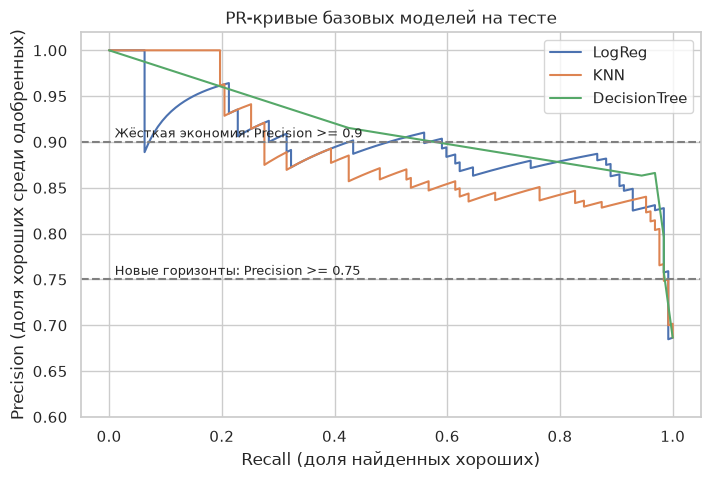

In [23]:
def plot_pr(probas, title):
    _fig, ax = plt.subplots(figsize=(8, 5))
    for name, proba in probas.items():
        prec, rec, _ = precision_recall_curve(y_test, proba)
        ax.plot(rec, prec, label=name)
    for strat, p in STRATEGIES.items():
        ax.axhline(p, ls="--", color="gray")
        ax.text(0.01, p + 0.005, f"{strat}: Precision >= {p}", fontsize=9)
    ax.set_xlabel("Recall (доля найденных хороших)")
    ax.set_ylabel("Precision (доля хороших среди одобренных)")
    ax.set_title(title)
    ax.set_ylim(0.6, 1.02)
    ax.legend()
    plt.show()


plot_pr(proba_base, "PR-кривые базовых моделей на тесте")

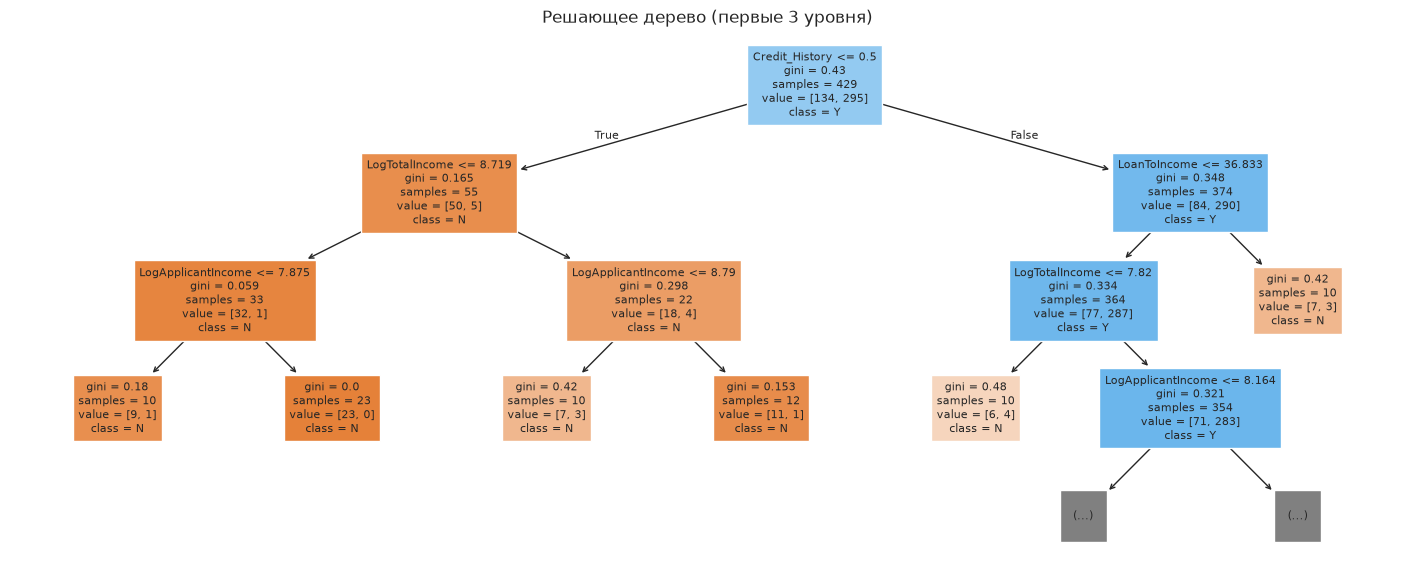

In [24]:
plt.figure(figsize=(18, 7))
tree = base_models["DecisionTree"][-1]
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["N", "Y"],
    filled=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Решающее дерево (первые 3 уровня)")
plt.show()

### 2.2. Ансамбли: случайный лес и градиентный бустинг

In [25]:
res_ens, proba_ens = evaluate_single_split(ensemble_models)
res_single = pd.concat([res_base, res_ens], ignore_index=True)
res_ens.round(3)

,model,strategy,threshold,precision,recall,approve_rate
0,RandomForest,Новые горизонты,0.292,0.750,0.992,0.908
1,RandomForest,Жёсткая экономия,0.681,0.903,0.732,0.557
2,GradientBoosting,Новые горизонты,0.137,0.750,0.992,0.908
3,GradientBoosting,Жёсткая экономия,0.754,0.902,0.654,0.497


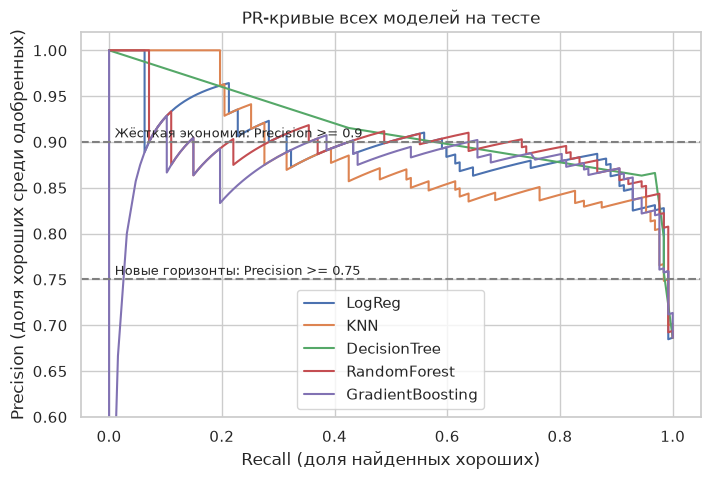

In [26]:
plot_pr({**proba_base, **proba_ens}, "PR-кривые всех моделей на тесте")

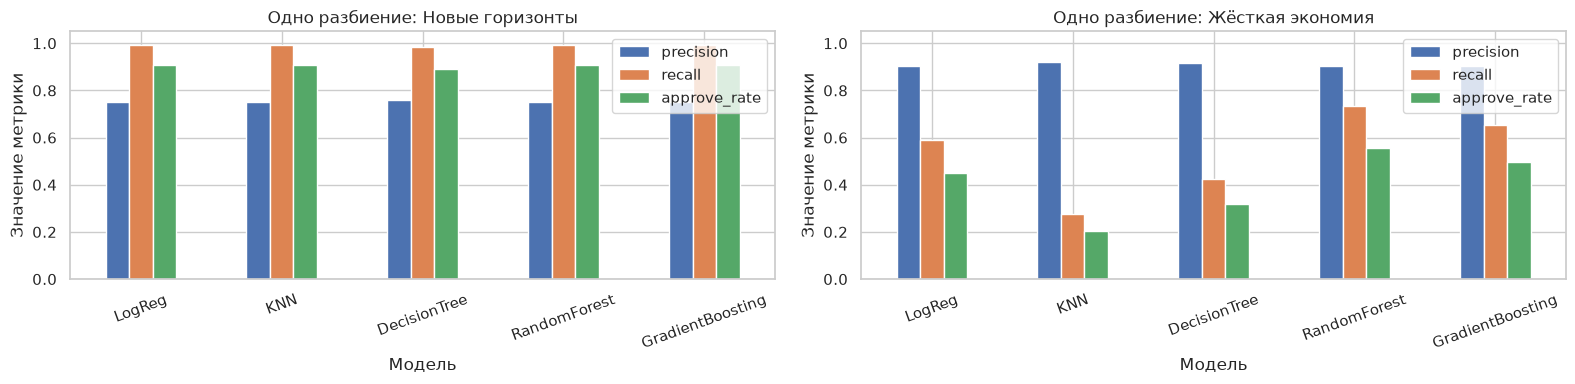

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (strat, sub) in zip(axes, res_single.groupby("strategy", sort=False)):
    sub.set_index("model")[["precision", "recall", "approve_rate"]].plot.bar(ax=ax)
    ax.set_title(f"Одно разбиение: {strat}")
    ax.set_ylabel("Значение метрики")
    ax.set_xlabel("Модель")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 2.3. Сравнение на 20 разбиениях

In [ ]:
all_models = {**base_models, **ensemble_models}
rows = []
for name, model in all_models.items():
    for strat, min_prec in STRATEGIES.items():
        m = evaluate_on_splits(model, X, y, min_prec)
        rows.append({"model": name, "strategy": strat, **m.to_dict()})
res_splits = pd.DataFrame(rows)
res_splits.pivot(
    index="model", columns="strategy", values=["precision", "recall", "approve_rate"]
).round(3)

precision                           recall  \
strategy         Жёсткая экономия Новые горизонты Жёсткая экономия   
model                                                                
DecisionTree                  NaN           0.765            0.000   
GradientBoosting            0.911           0.751            0.267   
KNN                         0.914           0.751            0.197   
LogReg                      0.923           0.751            0.230   
RandomForest                0.906           0.751            0.311   

                                     approve_rate                  
strategy         Новые горизонты Жёсткая экономия Новые горизонты  
model                                                              
DecisionTree               0.986            0.000           0.885  
GradientBoosting           0.987            0.202           0.901  
KNN                        0.990            0.149           0.904  
LogReg                     0.991            0.174           0.906  
RandomForest               0.991            0.236           0.905

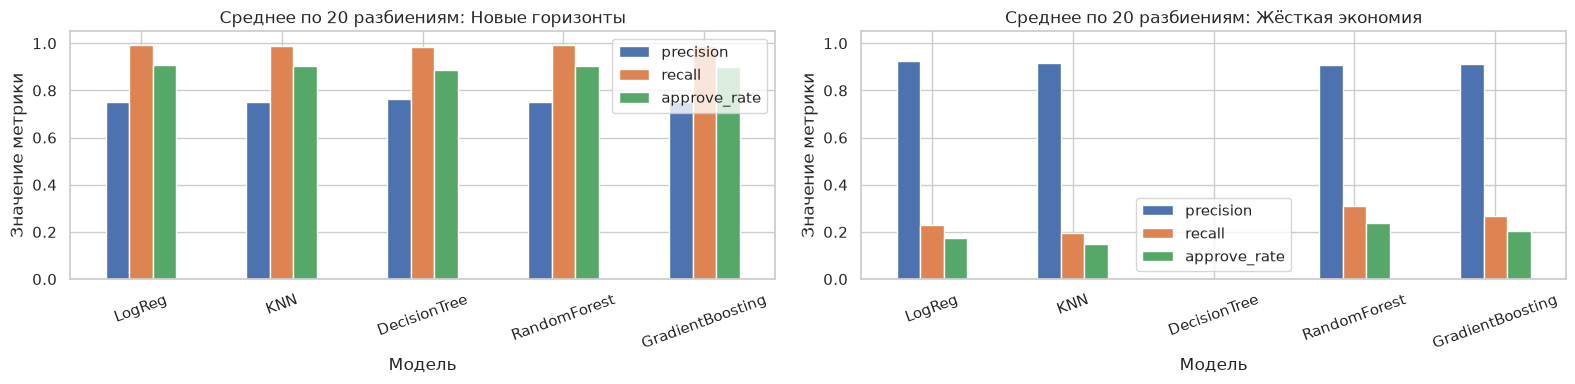

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (strat, sub) in zip(axes, res_splits.groupby("strategy", sort=False)):
    sub.set_index("model")[["precision", "recall", "approve_rate"]].plot.bar(ax=ax)
    ax.set_title(f"Среднее по 20 разбиениям: {strat}")
    ax.set_ylabel("Значение метрики")
    ax.set_xlabel("Модель")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 2.4. Случайный лес: зависимость от числа деревьев ("Жёсткая экономия")

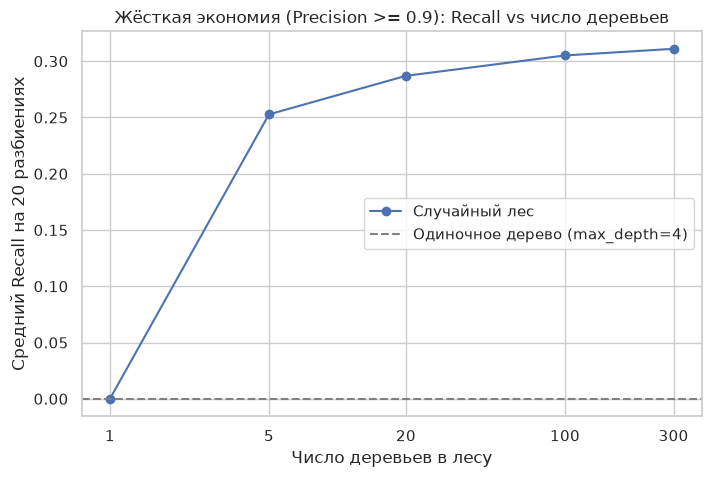

,n_trees,precision,recall,approve_rate
0,1,NaN,0.000,0.000
1,5,0.915,0.253,0.191
2,20,0.914,0.287,0.217
3,100,0.908,0.305,0.231
4,300,0.906,0.311,0.236


In [30]:
n_trees_list = [1, 5, 20, 100, 300]
forest_rows = []
for n in n_trees_list:
    rf = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=n,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    )
    m = evaluate_on_splits(rf, X, y, STRATEGIES["Жёсткая экономия"])
    forest_rows.append({"n_trees": n, **m.to_dict()})
forest_res = pd.DataFrame(forest_rows)

tree_recall = res_splits.query(
    "model == 'DecisionTree' and strategy == 'Жёсткая экономия'"
)["recall"].iloc[0]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(forest_res["n_trees"], forest_res["recall"], marker="o", label="Случайный лес")
ax.axhline(tree_recall, color="gray", ls="--", label="Одиночное дерево (max_depth=4)")
ax.set_xscale("log")
ax.set_xticks(n_trees_list)
ax.set_xticklabels(n_trees_list)
ax.set_xlabel("Число деревьев в лесу")
ax.set_ylabel("Средний Recall на 20 разбиениях")
ax.set_title("Жёсткая экономия (Precision >= 0.9): Recall vs число деревьев")
ax.legend()
plt.show()
forest_res.round(3)

DecisionTree: уникальных значений вероятности на тесте - 7
RandomForest: уникальных значений вероятности на тесте - 185


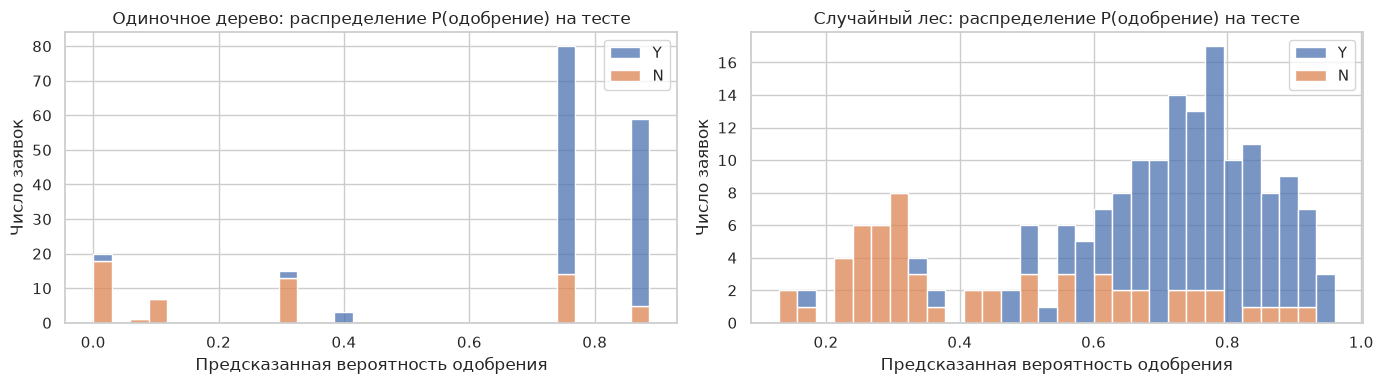

In [31]:
# Почему одно дерево плохо подходит для подбора порога: у него мало различных значений вероятности
for name in ["DecisionTree", "RandomForest"]:
    print(
        f"{name}: уникальных значений вероятности на тесте - {len(np.unique(proba_base.get(name, proba_ens.get(name))))}"
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name, proba in [
    (axes[0], "Одиночное дерево", proba_base["DecisionTree"]),
    (axes[1], "Случайный лес", proba_ens["RandomForest"]),
]:
    sns.histplot(
        x=proba,
        hue=y_test.map({1: "Y", 0: "N"}).values,
        bins=30,
        ax=ax,
        multiple="stack",
    )
    ax.set_title(f"{name}: распределение P(одобрение) на тесте")
    ax.set_xlabel("Предсказанная вероятность одобрения")
    ax.set_ylabel("Число заявок")
plt.tight_layout()
plt.show()

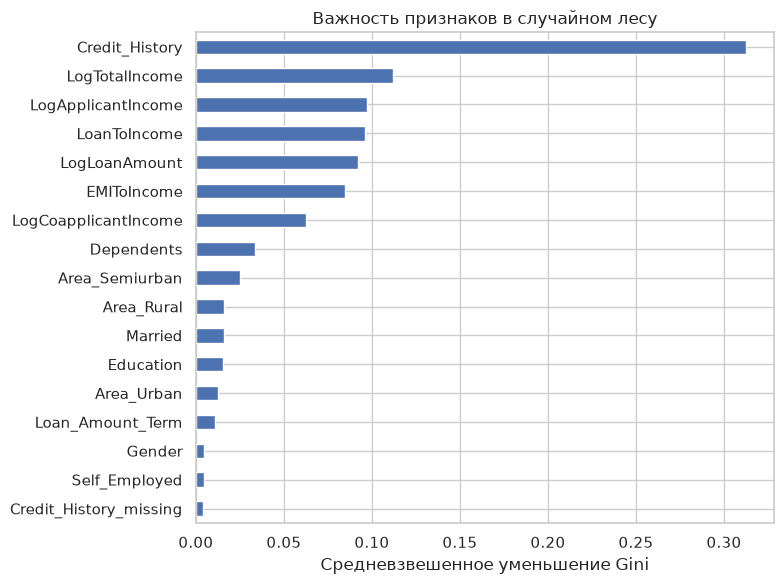

In [32]:
rf_final = ensemble_models["RandomForest"]
importances = pd.Series(
    rf_final[-1].feature_importances_, index=X.columns
).sort_values()
ax = importances.plot.barh(figsize=(8, 6))
ax.set_title("Важность признаков в случайном лесу")
ax.set_xlabel("Средневзвешенное уменьшение Gini")
plt.tight_layout()
plt.show()

### 2.5. Итоговое сравнение моделей

In [33]:
summary_tbl = res_splits.pivot(
    index="model", columns="strategy", values=["precision", "recall", "approve_rate"]
)
summary_tbl[("interpretability", "")] = summary_tbl.index.map(
    {
        "LogReg": "высокая (коэффициенты)",
        "DecisionTree": "высокая (правила)",
        "KNN": "низкая",
        "RandomForest": "средняя (важности)",
        "GradientBoosting": "средняя (важности)",
    }
)
summary_tbl.round(3)

precision                           recall  \
strategy         Жёсткая экономия Новые горизонты Жёсткая экономия   
model                                                                
DecisionTree                  NaN           0.765            0.000   
GradientBoosting            0.911           0.751            0.267   
KNN                         0.914           0.751            0.197   
LogReg                      0.923           0.751            0.230   
RandomForest                0.906           0.751            0.311   

                                     approve_rate                  \
strategy         Новые горизонты Жёсткая экономия Новые горизонты   
model                                                               
DecisionTree               0.986            0.000           0.885   
GradientBoosting           0.987            0.202           0.901   
KNN                        0.990            0.149           0.904   
LogReg                     0.991            0.174           0.906   
RandomForest               0.991            0.236           0.905   

                        interpretability  
strategy                                  
model                                     
DecisionTree           высокая (правила)  
GradientBoosting      средняя (важности)  
KNN                               низкая  
LogReg            высокая (коэффициенты)  
RandomForest          средняя (важности)

### 2.6. Ручной ввод данных заявителя

In [34]:
# Финальные модели обучаем на всех данных, пороги - по 20 разбиениям (медиана порогов),
# чтобы порог не зависел от одного удачного/неудачного теста
def robust_threshold(model, min_precision, n_splits=20):
    thrs = []
    for seed in range(n_splits):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.3, random_state=seed, stratify=y
        )
        proba = clone(model).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
        thr = find_threshold(y_te, proba, min_precision)
        if thr is not None:
            thrs.append(thr)
    return float(np.median(thrs))


FINAL = {
    "Новые горизонты": "LogReg",
    "Жёсткая экономия": "RandomForest",
}
final_models = {}
for strat, name in FINAL.items():
    model = clone(all_models[name]).fit(X, y)
    final_models[strat] = (
        name,
        model,
        robust_threshold(all_models[name], STRATEGIES[strat]),
    )
    print(f"{strat}: модель {name}, порог {final_models[strat][2]:.3f}")

Новые горизонты: модель LogReg, порог 0.120
Жёсткая экономия: модель RandomForest, порог 0.843


In [35]:
def predict_application(application: dict) -> pd.DataFrame:
    """Принимает данные заявителя в исходном формате датасета и возвращает решение по каждой стратегии"""
    row = prepare_features(pd.DataFrame([application]))[X.columns]
    out = []
    for strat, (name, model, thr) in final_models.items():
        p = model.predict_proba(row)[0, 1]
        out.append(
            {
                "Стратегия": strat,
                "Модель": name,
                "P(одобрение)": round(p, 3),
                "Порог": round(thr, 3),
                "Решение": "ОДОБРИТЬ" if p >= thr else "отправить в кредитный комитет",
            }
        )
    return pd.DataFrame(out)


# === Введите данные заявителя здесь ===
application = {
    "Gender": "Male",  # Male / Female
    "Married": "Yes",  # Yes / No
    "Dependents": "1",  # 0 / 1 / 2 / 3+
    "Education": "Graduate",  # Graduate / Not Graduate
    "Self_Employed": "No",  # Yes / No
    "ApplicantIncome": 4500,  # ежемесячный доход заявителя
    "CoapplicantIncome": 1500,  # доход созаёмщика (0, если нет)
    "LoanAmount": 130,  # сумма кредита, тыс.
    "Loan_Amount_Term": 360,  # срок, мес.
    "Credit_History": 1,  # 1 / 0 / None (нет данных)
    "Property_Area": "Semiurban",  # Urban / Semiurban / Rural
}
predict_application(application)

,Стратегия,Модель,P(одобрение),Порог,Решение
0,Новые горизонты,LogReg,0.918,0.120,ОДОБРИТЬ
1,Жёсткая экономия,RandomForest,0.868,0.843,ОДОБРИТЬ


In [36]:
# Интерактивный вариант: ввод с клавиатуры (запусти, поставив INTERACTIVE = True)
INTERACTIVE = True


def ask(prompt, cast=str, default=None):
    raw = input(f"{prompt} [{default}]: ").strip()
    return cast(raw) if raw else default


if INTERACTIVE:
    ch = ask("Credit_History (1 / 0 / пусто - нет данных)", str, "1")
    application = {
        "Gender": ask("Gender (Male/Female)", str, "Male"),
        "Married": ask("Married (Yes/No)", str, "Yes"),
        "Dependents": ask("Dependents (0/1/2/3+)", str, "0"),
        "Education": ask("Education (Graduate/Not Graduate)", str, "Graduate"),
        "Self_Employed": ask("Self_Employed (Yes/No)", str, "No"),
        "ApplicantIncome": ask("ApplicantIncome", float, 4000.0),
        "CoapplicantIncome": ask("CoapplicantIncome", float, 0.0),
        "LoanAmount": ask("LoanAmount, тыс.", float, 120.0),
        "Loan_Amount_Term": ask("Loan_Amount_Term, мес.", float, 360.0),
        "Credit_History": float(ch) if ch in ("0", "1") else None,
        "Property_Area": ask("Property_Area (Urban/Semiurban/Rural)", str, "Urban"),
    }
    display(predict_application(application))

,Стратегия,Модель,P(одобрение),Порог,Решение
0,Новые горизонты,LogReg,0.000,0.120,отправить в кредитный комитет
1,Жёсткая экономия,RandomForest,0.296,0.843,отправить в кредитный комитет


In [37]:
# Несколько показательных примеров для руководства
examples = pd.DataFrame(
    [
        {**application, "Credit_History": 0},
        {
            **application,
            "Property_Area": "Rural",
            "ApplicantIncome": 2500,
            "CoapplicantIncome": 0,
            "LoanAmount": 200,
        },
        {**application, "Married": "No", "Credit_History": None},
    ]
)
for i, ex in examples.iterrows():
    print(
        f"Пример {i + 1}: Credit_History={ex['Credit_History']}, район={ex['Property_Area']}, "
        f"доход={ex['ApplicantIncome'] + ex['CoapplicantIncome']:.0f}, кредит={ex['LoanAmount']}"
    )
    display(predict_application(ex.to_dict()))

Пример 1: Credit_History=0.0, район=Urban, доход=1200, кредит=400.0


,Стратегия,Модель,P(одобрение),Порог,Решение
0,Новые горизонты,LogReg,0.000,0.120,отправить в кредитный комитет
1,Жёсткая экономия,RandomForest,0.176,0.843,отправить в кредитный комитет


Пример 2: Credit_History=1.0, район=Rural, доход=2500, кредит=200.0


,Стратегия,Модель,P(одобрение),Порог,Решение
0,Новые горизонты,LogReg,0.013,0.120,отправить в кредитный комитет
1,Жёсткая экономия,RandomForest,0.347,0.843,отправить в кредитный комитет


Пример 3: Credit_History=nan, район=Urban, доход=1200, кредит=400.0


,Стратегия,Модель,P(одобрение),Порог,Решение
0,Новые горизонты,LogReg,0.000,0.120,отправить в кредитный комитет
1,Жёсткая экономия,RandomForest,0.295,0.843,отправить в кредитный комитет


## Выводы по заданию 2

На одном разбиении в стратегии "Новые горизонты" все модели почти одинаковы: Recall около 0.99 при одобрении примерно 90% заявок. Так получается потому, что хороших и так 69%, и чтобы поднять долю до 75%, достаточно отсечь плохую кредитную историю. В "Жёсткой экономии" модели уже различаются: логистическая регрессия даёт Recall 0.59, дерево 0.43, KNN 0.28, а случайный лес и бустинг 0.73 и 0.65.

На 20 разбиениях картина гораздо скромнее, и первое разбиение оказалось просто удачным. В "Жёсткой экономии" средний Recall у леса 0.31, у бустинга 0.27, у логистической регрессии 0.23, у KNN 0.20, а одиночное дерево почти никогда не дотягивает до 90% точности и никого не одобряет. Лес из 1 дерева даёт 0, из 5 уже 0.25, из 20 около 0.29, и к 100-300 деревьям выходит на плато 0.31.

Ансамбли помогли именно там, где нужна высокая точность. Одно дерево выдаёт лишь несколько разных вероятностей (по числу листьев) и сильно зависит от обучающей выборки, поэтому порог можно поставить только грубо. Лес усредняет сотни деревьев, обученных на разных бутстрэп-выборках и подмножествах признаков, их ошибки слабо связаны и гасятся, а вероятности становятся гладкими, что позволяет аккуратно отобрать самых надёжных клиентов. Бустинг уменьшает смещение, но на 600 строках легче переобучается и немного уступает лесу. Чудес при этом нет, все модели упираются в кредитную историю, а выигрыш ансамблей в более точном ранжировании внутри группы с хорошей историей.

Для "Новых горизонтов" я выбираю логистическую регрессию: по Precision, Recall и доле одобрений все модели равны, а она самая простая и понятная, её коэффициенты легко объяснить руководству. Надо помнить, что при таком низком пороге она одобряет и часть клиентов с плохой историей, так как 75% точности достигается в среднем по потоку. Для "Жёсткой экономии" лучший выбор - случайный лес из 300 деревьев: средний Recall 0.31 и около 24% одобренных заявок при точности 0.91; интерпретируемость у него ниже, но важности признаков дают общее понимание. KNN и одиночное дерево не рекомендую из-за слабого и нестабильного результата.

Для ручной проверки финальные модели обучены на всём датасете, а порог взят как медиана порогов по 20 разбиениям, чтобы он не зависел от одного теста.


## Задание 3 [1 балл]

Подведи итоги: дай банку свою рекомендацию, какую стратегию и какую модель выбрать. Возможно, для решения нужно дополнительное исследование — опиши, что ещё можно посмотреть.

## Рекомендация банку

Я рекомендую стратегию "Жёсткая экономия" со случайным лесом и порогом около 0.84. Модель сама одобрит примерно четверть заявок, из которых не меньше 90% хорошие, а остальные по-прежнему уйдут в комитет: нагрузка на комитет снизится примерно на четверть почти без роста риска, что для банка в трудном положении безопаснее всего. "Новые горизонты" сейчас запускать не стоит: стратегия фактически одобряет почти всех, работает ровно на границе безубыточности и пропускает часть клиентов с плохой историей, так что любой сдвиг потока заявок уведёт банк в убыток. Если руководство всё же выберет её, лучше использовать логистическую регрессию или даже простое правило по кредитной истории.

Перед внедрением стоит сделать ещё несколько вещей. Главное, что целевая переменная - это решение комитета, а не факт возврата кредита, поэтому нужны данные о реальных дефолтах. Порог нужно подбирать на отдельной валидационной выборке и проверять на свежих заявках, а не на тесте. Имеет смысл подобрать гиперпараметры ансамблей и откалибровать вероятности, перевести Precision и Recall в деньги и выбирать порог по ожидаемой прибыли, проверить, что модель не дискриминирует по полу и браку, и собрать больше данных, потому что 614 заявок для таких выводов мало.
